# Face classification and verification
# Dataset: https://www.kaggle.com/c/11-785-fall-20-homework-2-part-2/overview

Set DATA_ROOT to the dataset on your machine. Run All displays the existing results. To train or evaluate, enable the corresponding switches below. Use a new RUN_NAME for a fresh experiment.

In [ ]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown, Image as DisplayImage

PROJECT_ROOT = None  # Example: Path('/Users/your_name/Desktop/Final_Project_30082')
RUN_NAME = 'face_classification'
EXPECTED_TASK = 'face'
CHECK_MODEL_HASH = True  # Reads checkpoint bytes only; never loads a model.

if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_ROOT = next((p for p in candidates if (p / 'app.py').is_file()
                         or (p / 'runs' / RUN_NAME).is_dir()
                         or (p / 'reports' / RUN_NAME).is_dir()), Path.cwd())
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
RUN_DIR = PROJECT_ROOT / 'runs' / RUN_NAME
REPORT_DIR = PROJECT_ROOT / 'reports' / RUN_NAME
MODEL_DIR = PROJECT_ROOT / 'models' / RUN_NAME

print('Project:', PROJECT_ROOT)
print('Run:', RUN_DIR)
print('Exported reports:', REPORT_DIR)
if not RUN_DIR.is_dir() and not REPORT_DIR.is_dir():
    print('No results folder found. Check PROJECT_ROOT or save the Terminal results first.')
DATA_ROOT = PROJECT_ROOT / '11-785-fall-20-homework-2-part-2'  # Set to the extracted dataset or FER CSV.
RUN_TRAINING = False
RUN_EVALUATION = False
RESUME = False

In [ ]:
from argparse import Namespace
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
from PIL import Image
import random
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, classification_report, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import tempfile
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights, resnet18
from tqdm.auto import tqdm

## Training utilities

In [ ]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def choose_device(requested="auto"):
    if requested != "auto":
        return torch.device(requested)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")


def atomic_torch_save(value, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fd, temporary = tempfile.mkstemp(prefix="checkpoint_", suffix=".pt", dir=path.parent)
    os.close(fd)
    try:
        torch.save(value, temporary)
        os.replace(temporary, path)
    finally:
        Path(temporary).unlink(missing_ok=True)


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def runtime_versions():
    import platform
    import torchvision

    return {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__)}

## Model and image transforms

In [ ]:
class FaceClassifier(nn.Module):
    def __init__(self, num_classes, embedding_dim=128, pretrained=False,
                 train_backbone="layer4"):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        self.backbone = resnet18(weights=weights)
        self.backbone.fc = nn.Identity()
        self.embedding = nn.Linear(512, embedding_dim)
        self.classifier = nn.Linear(embedding_dim, num_classes)
        if train_backbone not in {"all", "layer4"}:
            raise ValueError("train_backbone must be all or layer4")
        self.train_backbone = train_backbone
        if train_backbone == "layer4":
            for name, parameter in self.backbone.named_parameters():
                parameter.requires_grad = name.startswith("layer4.")

    def train(self, mode=True):
        super().train(mode)
        if mode and self.train_backbone == "layer4":
            self.backbone.eval()
            self.backbone.layer4.train()
        return self

    def encode(self, images):
        return F.normalize(self.embedding(self.backbone(images)), p=2, dim=1)

    def forward(self, images):
        features = self.embedding(self.backbone(images))
        return self.classifier(features)


def face_transform(image_size=224, training=False):
    operations = [T.Resize((image_size, image_size))]
    if training:
        operations.extend([T.RandomHorizontalFlip(),
                           T.ColorJitter(brightness=0.15, contrast=0.15)])
    operations.extend([T.ToTensor(),
                       T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    return T.Compose(operations)


def build_model(config, pretrained=False):
    if config["task"] == "face":
        return FaceClassifier(len(config["classes"]), config["embedding_dim"],
                              pretrained, config["train_backbone"])
    raise ValueError("Unknown task in model config")


def load_model(path, device="cpu"):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if checkpoint.get("format_version") != 1:
        raise ValueError("Unsupported checkpoint format.")
    model = build_model(checkpoint["config"], pretrained=False)
    model.load_state_dict(checkpoint["model_state"])
    model.to(device).eval()
    return model, checkpoint["config"]

## Dataset and splits

In [ ]:
class FolderSamples(Dataset):
    def __init__(self, samples, classes, transform):
        self.samples = list(samples)
        self.classes = list(classes)
        self.targets = [int(label) for _, label in self.samples]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            return self.transform(image.convert("RGB")), label


def folder_samples(directory, classes=None):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError(f"Missing image directory: {directory}")
    folder = ImageFolder(directory)
    classes = folder.classes if classes is None else list(classes)
    mapping = {name: index for index, name in enumerate(classes)}
    unknown = set(folder.classes) - set(classes)
    if unknown:
        raise ValueError(f"Unknown labels in {directory}: {sorted(unknown)}")
    samples = [(path, mapping[folder.classes[label]]) for path, label in folder.samples]
    return samples, classes


def face_datasets(root, image_size=224):
    root = Path(root)
    base = root / "classification_data" if (root / "classification_data").is_dir() else root
    train, classes = folder_samples(base / "train_data")
    val, _ = folder_samples(base / "val_data", classes)
    test, _ = folder_samples(base / "test_data", classes)
    datasets = {
        "train": FolderSamples(train, classes, face_transform(image_size, True)),
        "val": FolderSamples(val, classes, face_transform(image_size)),
        "test": FolderSamples(test, classes, face_transform(image_size)),
    }
    return datasets, {"source": str(base.resolve()), "split_policy": "provided train_data/val_data/test_data"}


def save_manifest(datasets, output):
    rows = []
    for split, dataset in datasets.items():
        if hasattr(dataset, "samples"):
            for path, label in dataset.samples:
                rows.append({"split": split, "sample": str(path), "label": label,
                             "class_name": dataset.classes[label]})
        else:
            for row_id, label in zip(dataset.row_ids, dataset.targets):
                rows.append({"split": split, "sample": f"csv_row:{row_id}", "label": label,
                             "class_name": dataset.classes[label]})
    frame = pd.DataFrame(rows)
    frame.to_csv(Path(output) / "split_manifest.csv", index=False)
    return frame.groupby(["split", "class_name"]).size().unstack(fill_value=0)

## Training

In [ ]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    model.train(optimizer is not None)
    total_loss = 0.0
    actual, predicted = [], []
    context = torch.enable_grad() if optimizer is not None else torch.no_grad()
    with context:
        for images, labels in tqdm(loader, leave=False, desc="train" if optimizer else "validation"):
            images, labels = images.to(device), labels.to(device)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if optimizer is not None:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                optimizer.step()
            total_loss += float(loss.detach()) * len(labels)
            actual.extend(labels.cpu().tolist())
            predicted.extend(logits.argmax(1).detach().cpu().tolist())
    return {"loss": total_loss / len(actual), "accuracy": float(accuracy_score(actual, predicted)),
            "macro_f1": float(f1_score(actual, predicted, average="macro", zero_division=0))}


def train(args):
    seed_everything(args.seed)
    device = choose_device(args.device)
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    resume_path = output / "last.pt"
    if resume_path.exists() and not args.resume:
        raise FileExistsError("last.pt exists. Use --resume or choose a new output folder.")
    if args.resume and not resume_path.exists():
        raise FileNotFoundError(f"No checkpoint to resume: {resume_path}")
    datasets, metadata = face_datasets(args.data_root, args.image_size)
    classes = datasets["train"].classes
    if len(classes) < 2:
        raise ValueError("Training requires at least two classes")
    config = {"task": args.task, "architecture": "resnet18_embedding" if args.task == "face" else "emotion_cnn",
              "classes": classes, "embedding_dim": args.embedding_dim,
              "train_backbone": args.train_backbone, "image_size": args.image_size if args.task == "face" else 48,
              "seed": args.seed, "val_fraction": args.val_fraction,
              "initial_weights": "random" if args.from_scratch or args.task == "emotion" else "ImageNet",
              "preprocessing": "rgb_imagenet_resize" if args.task == "face" else "gray48_normalize_0.5"}
    settings = {"batch_size": args.batch_size, "lr": args.lr, "weight_decay": args.weight_decay,
                "class_weights": args.class_weights, "patience": args.patience}
    model = build_model(config, pretrained=not args.from_scratch and not args.resume).to(device)
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.AdamW(trainable, lr=args.lr, weight_decay=args.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    generator = torch.Generator().manual_seed(args.seed)
    best, start_epoch, bad_epochs, history = -1.0, 0, 0, []
    state = None
    if args.resume:
        state = torch.load(resume_path, map_location="cpu", weights_only=True)
        if state["config"] != config or state["training_settings"] != settings:
            raise ValueError("Resume settings differ. Restore the original settings or start a new run.")
        model.load_state_dict(state["model_state"])
        optimizer.load_state_dict(state["optimizer_state"])
        scheduler.load_state_dict(state["scheduler_state"])
        best, start_epoch = state["best_score"], state["epoch"]
        bad_epochs, history = state["bad_epochs"], state["history"]
        torch.set_rng_state(state["torch_rng"])
        random.setstate(state["python_rng"])
        numpy_state = state["numpy_rng"]
        np.random.set_state((numpy_state[0], np.array(numpy_state[1], dtype=np.uint32),
                             numpy_state[2], numpy_state[3], numpy_state[4]))
        generator.set_state(state["loader_rng"])
        if device.type == "cuda" and state.get("cuda_rng") is not None:
            torch.cuda.set_rng_state_all(state["cuda_rng"])
    if start_epoch >= args.epochs:
        print(f"Already completed {start_epoch} epochs. Increase --epochs to continue.")
        return
    manifest_path = output / "split_manifest.csv"
    if state is not None and manifest_path.exists():
        previous_manifest_hash = file_sha256(manifest_path)
        if previous_manifest_hash != state["manifest_sha256"]:
            raise ValueError("The saved split manifest was modified")
    counts = save_manifest(datasets, output)
    manifest_hash = file_sha256(manifest_path)
    if state is not None and manifest_hash != state["manifest_sha256"]:
        raise ValueError("Dataset paths, labels, or splits changed since the checkpoint")
    counts.to_csv(output / "class_counts.csv")
    weights = None
    if args.class_weights:
        frequencies = np.bincount(datasets["train"].targets, minlength=len(classes))
        if np.any(frequencies == 0):
            raise ValueError("Every class needs training examples")
        weights = torch.tensor(len(datasets["train"]) / (len(classes) * frequencies),
                               dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights)
    loaders = {split: DataLoader(dataset, batch_size=args.batch_size, shuffle=split == "train",
                                num_workers=args.workers, pin_memory=device.type == "cuda",
                                generator=generator if split == "train" else None)
               for split, dataset in datasets.items() if split != "test"}
    metadata.update({"counts": {key: len(value) for key, value in datasets.items()},
                     "versions": runtime_versions(), "selection_metric": "val_accuracy" if args.task == "face" else "val_macro_f1",
                     "device": str(device), "manifest_sha256": manifest_hash})
    write_json(output / "config.json", config)
    write_json(output / "run_metadata.json", metadata)
    write_json(output / "training_settings.json", {**settings, "target_epochs": args.epochs, "workers": args.workers})
    print(f"Device: {device}. Classes: {len(classes)}. Split sizes: {metadata['counts']}")
    for epoch in range(start_epoch, args.epochs):
        training = run_epoch(model, loaders["train"], criterion, device, optimizer)
        validation = run_epoch(model, loaders["val"], criterion, device)
        score = validation["accuracy" if args.task == "face" else "macro_f1"]
        improved = score > best
        bad_epochs = 0 if improved else bad_epochs + 1
        best = max(best, score)
        scheduler.step(score)
        row = {"epoch": epoch + 1, "lr": optimizer.param_groups[0]["lr"],
               **{f"train_{key}": value for key, value in training.items()},
               **{f"val_{key}": value for key, value in validation.items()}}
        history.append(row)
        inference = {"format_version": 1, "config": config, "model_state": model.state_dict(),
                     "epoch": epoch + 1, "best_score": best, "training_settings": settings}
        if improved:
            atomic_torch_save(inference, output / "best.pt")
        numpy_state = np.random.get_state()
        checkpoint = {**inference, "optimizer_state": optimizer.state_dict(),
                      "scheduler_state": scheduler.state_dict(), "bad_epochs": bad_epochs,
                      "history": history, "manifest_sha256": manifest_hash,
                      "torch_rng": torch.get_rng_state(), "python_rng": random.getstate(),
                      "numpy_rng": (numpy_state[0], numpy_state[1].tolist(), numpy_state[2],
                                    numpy_state[3], numpy_state[4]),
                      "loader_rng": generator.get_state(),
                      "cuda_rng": torch.cuda.get_rng_state_all() if device.type == "cuda" else None}
        atomic_torch_save(checkpoint, resume_path)
        pd.DataFrame(history).to_csv(output / "history.csv", index=False)
        print(json.dumps(row))
        if bad_epochs >= args.patience:
            print(f"Early stopping. Best validation score: {best:.4f}")
            break
    print(f"Saved model: {output / 'best.pt'}")

## Verification scores

In [ ]:
def read_pairs(path, root):
    root = Path(root).resolve()
    pairs, seen = [], {}
    for number, line in enumerate(Path(path).read_text(encoding="utf-8").splitlines(), start=1):
        if not line.strip():
            continue
        fields = line.split()
        if len(fields) != 3 or fields[2] not in {"0", "1"}:
            raise ValueError(f"Line {number}: expected image1 image2 label(0/1)")
        images = []
        for relative in fields[:2]:
            target = (root / relative).resolve()
            if not target.is_relative_to(root):
                raise ValueError(f"Line {number}: image path outside data root")
            images.append(target)
        key = tuple(sorted(str(image) for image in images))
        label = int(fields[2])
        if key in seen and seen[key] != label:
            raise ValueError(f"Conflicting labels for pair at line {number}")
        seen[key] = label
        pairs.append((images[0], images[1], label))
    if not pairs or {pair[2] for pair in pairs} != {0, 1}:
        raise ValueError("ROC evaluation requires both same-person and different-person pairs")
    missing = sorted({str(image) for pair in pairs for image in pair[:2] if not image.is_file()})
    if missing:
        raise FileNotFoundError(f"{len(missing)} referenced images missing. Examples: {missing[:5]}")
    return pairs


def pair_scores(pairs, embeddings):
    first = np.stack([embeddings[str(pair[0])] for pair in pairs])
    second = np.stack([embeddings[str(pair[1])] for pair in pairs])
    first = first / np.maximum(np.linalg.norm(first, axis=1, keepdims=True), 1e-12)
    second = second / np.maximum(np.linalg.norm(second, axis=1, keepdims=True), 1e-12)
    return {"cosine": np.sum(first * second, axis=1),
            "negative_euclidean": -np.linalg.norm(first - second, axis=1)}


def choose_threshold(labels, scores, target_fpr=0.01):
    if not 0 <= target_fpr <= 1:
        raise ValueError("target_fpr must be in [0, 1]")
    fpr, tpr, thresholds = roc_curve(labels, scores, drop_intermediate=False)
    candidates = np.flatnonzero((fpr <= target_fpr) & np.isfinite(thresholds))
    if len(candidates):
        index = int(candidates[np.argmax(tpr[candidates])])
        threshold = float(thresholds[index])
    else:
        threshold = float(np.max(scores) + 1e-6)
    return threshold


def score_summary(labels, scores, threshold):
    labels = np.asarray(labels)
    accepted = np.asarray(scores) >= threshold
    return {"roc_auc": float(roc_auc_score(labels, scores)), "threshold": float(threshold),
            "tpr": float(accepted[labels == 1].mean()),
            "fpr": float(accepted[labels == 0].mean()),
            "accuracy": float((accepted == labels).mean())}

## Evaluation

In [ ]:
class PairImages(Dataset):
    def __init__(self, paths, image_size):
        self.paths = list(paths)
        self.transform = face_transform(image_size)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert("RGB")), str(self.paths[index])


def plot_history(run, output):
    history = Path(run) / "history.csv"
    if not history.is_file():
        return
    frame = pd.read_csv(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for prefix, label in [("train", "Train"), ("val", "Validation")]:
        axes[0].plot(frame.epoch, frame[f"{prefix}_loss"], label=label)
        axes[1].plot(frame.epoch, frame[f"{prefix}_accuracy"], label=label)
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(Path(output) / "training_curves.png", dpi=160)
    plt.close(fig)


def evaluate_classification(args):
    device = choose_device(args.device)
    model, config = load_model(args.checkpoint, device)
    datasets, _ = face_datasets(args.data_root, config["image_size"])
    dataset = datasets[args.split]
    if dataset.classes != config["classes"]:
        raise ValueError("Dataset class order differs from the trained model")
    loader = DataLoader(dataset, batch_size=args.batch_size, num_workers=args.workers)
    actual, predicted = [], []
    with torch.inference_mode():
        for images, labels in loader:
            predicted.extend(model(images.to(device)).argmax(1).cpu().tolist())
            actual.extend(labels.tolist())
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    metrics = {"task": config["task"], "split": args.split, "samples": len(actual),
               "accuracy": float(accuracy_score(actual, predicted)),
               "balanced_accuracy": float(balanced_accuracy_score(actual, predicted)),
               "macro_f1": float(f1_score(actual, predicted, average="macro", zero_division=0)),
               "checkpoint_sha256": file_sha256(args.checkpoint)}
    write_json(output / "classification_metrics.json", metrics)
    report = classification_report(actual, predicted, labels=list(range(len(dataset.classes))),
                                   target_names=dataset.classes, output_dict=True, zero_division=0)
    write_json(output / "classification_report.json", report)
    pd.DataFrame({"true_label": actual, "predicted_label": predicted}).to_csv(output / "predictions.csv", index=False)
    if len(dataset.classes) <= 20:
        fig, ax = plt.subplots(figsize=(8, 7))
        ConfusionMatrixDisplay.from_predictions(actual, predicted,
                                                labels=list(range(len(dataset.classes))),
                                                display_labels=dataset.classes,
                                                xticks_rotation=45, ax=ax, colorbar=False)
        ax.set_title(f"{config['task']} / {args.split}")
        fig.tight_layout()
        fig.savefig(output / "confusion_matrix.png", dpi=160)
        plt.close(fig)
    plot_history(Path(args.checkpoint).parent, output)
    print(metrics)


def evaluate_verification(args):
    device = choose_device(args.device)
    model, config = load_model(args.checkpoint, device)
    if config["task"] != "face":
        raise ValueError("Verification requires a face embedding model")
    evaluation_pairs = read_pairs(args.pairs, args.data_root)
    calibration_pairs = read_pairs(args.calibration_pairs, args.data_root) if args.calibration_pairs else evaluation_pairs
    if args.calibration_pairs:
        calibration_images = {str(path) for pair in calibration_pairs for path in pair[:2]}
        evaluation_images = {str(path) for pair in evaluation_pairs for path in pair[:2]}
        if calibration_images & evaluation_images:
            raise ValueError("Calibration and evaluation share image paths. Use disjoint sets or omit --calibration-pairs.")
    paths = sorted({path for pair in evaluation_pairs + calibration_pairs for path in pair[:2]})
    loader = DataLoader(PairImages(paths, config["image_size"]), batch_size=args.batch_size,
                        num_workers=args.workers)
    embeddings = {}
    with torch.inference_mode():
        for images, names in loader:
            vectors = model.encode(images.to(device)).cpu().numpy()
            embeddings.update(zip(names, vectors))
    scores = pair_scores(evaluation_pairs, embeddings)
    calibration_scores = pair_scores(calibration_pairs, embeddings)
    labels = [pair[2] for pair in evaluation_pairs]
    calibration_labels = [pair[2] for pair in calibration_pairs]
    output = Path(args.output)
    output.mkdir(parents=True, exist_ok=True)
    fingerprint = file_sha256(args.checkpoint)
    scope = "separate image-disjoint calibration; identity independence not established" if args.calibration_pairs else "validation only; threshold selected on these same pairs"
    metrics, thresholds = {}, {}
    fig, ax = plt.subplots(figsize=(6, 5))
    for name, values in scores.items():
        threshold = choose_threshold(calibration_labels, calibration_scores[name], args.target_fpr)
        metrics[name] = score_summary(labels, values, threshold)
        thresholds[name] = threshold
        fpr, tpr, _ = roc_curve(labels, values)
        ax.plot(fpr, tpr, label=f"{name}: AUC={metrics[name]['roc_auc']:.4f}")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Face verification ROC")
    ax.legend()
    fig.tight_layout()
    fig.savefig(output / "roc.png", dpi=160)
    plt.close(fig)
    result = {"scope": scope, "pairs": len(labels), "target_calibration_fpr": args.target_fpr,
              "checkpoint_sha256": fingerprint, "pairs_sha256": file_sha256(args.pairs),
              "metrics": metrics,
              "note": "Pairwise thresholds require separate validation for 1:N gallery matching. No guaranteed webcam FPR."}
    write_json(output / "verification_metrics.json", result)
    write_json(output / "thresholds.json", {"format_version": 1, "checkpoint_sha256": fingerprint,
                                            "score_rule": "accept if score >= threshold",
                                            "scope": scope, "thresholds": thresholds})
    pd.DataFrame({"image1": [str(pair[0]) for pair in evaluation_pairs],
                  "image2": [str(pair[1]) for pair in evaluation_pairs],
                  "label": labels, **scores}).to_csv(output / "pair_scores.csv", index=False)
    print(result)

## Run training and evaluation

In [ ]:
if RUN_TRAINING:
    if (RUN_DIR / 'best.pt').exists() and not RESUME:
        raise FileExistsError('Choose a new RUN_NAME or resume the existing run.')
    options = Namespace(task='face', data_root=DATA_ROOT, output=RUN_DIR,
                        epochs=15, batch_size=32, lr=0.001, weight_decay=0.0001,
                        embedding_dim=128, image_size=224, train_backbone='layer4',
                        seed=42, workers=0, patience=5, val_fraction=0.15,
                        device='auto', resume=RESUME, from_scratch=False, class_weights=False)
    train(options)

In [ ]:
if RUN_EVALUATION:
    options = Namespace(checkpoint=RUN_DIR / 'best.pt', data_root=DATA_ROOT,
                        output=RUN_DIR / 'classification', split='test', batch_size=32,
                        workers=0, device='auto')
    evaluate_classification(options)
    options.pairs = DATA_ROOT / 'verification_pairs_val.txt'
    options.calibration_pairs = None
    options.target_fpr = 0.01
    options.output = RUN_DIR / 'verification'
    evaluate_verification(options)

In [2]:
SEARCH_DIRS = [RUN_DIR, REPORT_DIR, MODEL_DIR]

def find_file(relative):
    return next((base / relative for base in SEARCH_DIRS
                 if (base / relative).is_file()), None)

def read_json(relative):
    path = find_file(relative)
    if path is None:
        return None
    try:
        value = json.loads(path.read_text(encoding='utf-8'))
        if not isinstance(value, dict):
            print(f'{relative}: expected a JSON object.')
            return None
        return value
    except (OSError, json.JSONDecodeError) as error:
        print(f'{relative} is not readable yet: {error}')
        return None

def read_csv(relative, **options):
    path = find_file(relative)
    if path is None:
        return None
    try:
        return pd.read_csv(path, **options)
    except (OSError, pd.errors.EmptyDataError, pd.errors.ParserError) as error:
        print(f'{relative} is not readable yet: {error}')
        return None

def show_image(relative):
    path = find_file(relative)
    if path is None:
        print(f'Pending: {relative}')
    else:
        display(DisplayImage(filename=str(path)))

def sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

checkpoint_path = find_file('best.pt')
checkpoint_hash = sha256(checkpoint_path) if CHECK_MODEL_HASH and checkpoint_path else None

def check_evaluation_identity(metrics, label):
    evaluated_hash = metrics.get('checkpoint_sha256')
    if checkpoint_hash and evaluated_hash:
        if evaluated_hash != checkpoint_hash:
            display(Markdown(f'**{label}: these saved results use a different checkpoint '
                             'from the current best.pt. Treat them as an older/different '
                             'model snapshot, or rerun evaluation in Terminal.**'))
        else:
            print(f'{label}: checkpoint matches current best.pt.')
    elif evaluated_hash:
        print(f'{label}: recorded checkpoint SHA-256: {evaluated_hash}')
    else:
        print(f'{label}: checkpoint identity is not available.')

## 2. Saved configuration and dataset counts
Configuration describes the run; it is not evidence of model performance.
Missing files are shown as pending instead of starting training automatically.

In [3]:
config = read_json('config.json') or {}
settings = read_json('training_settings.json') or {}
metadata = read_json('run_metadata.json') or {}
if config:
    if config.get('task') != EXPECTED_TASK:
        display(Markdown('**Task mismatch. Check RUN_DIR before interpreting these results.**'))
    fields = ['task', 'architecture', 'initial_weights', 'embedding_dim', 'image_size',
              'train_backbone', 'preprocessing', 'seed']
    details = {key: config[key] for key in fields if key in config}
    details['number_of_classes'] = len(config.get('classes', []))
    display(pd.DataFrame(details.items(), columns=['Setting', 'Value']))
    if EXPECTED_TASK == 'emotion' and config.get('classes'):
        display(pd.DataFrame({'class_index': range(len(config['classes'])),
                              'class_name': config['classes']}))
else:
    print('Pending: config.json')
if settings:
    display(pd.DataFrame(settings.items(), columns=['Training setting', 'Value']))
if metadata.get('versions'):
    display(pd.DataFrame(metadata['versions'].items(), columns=['Runtime', 'Version']))
if metadata.get('split_policy'):
    print('Split policy:', metadata['split_policy'])

counts = read_csv('class_counts.csv', index_col=0)
if counts is not None:
    counts = counts.apply(pd.to_numeric, errors='coerce').fillna(0)
    summary = pd.DataFrame({'images': counts.sum(axis=1).astype(int),
                            'represented_classes': (counts > 0).sum(axis=1)})
    summary.index.name = 'split'
    display(summary)
elif metadata.get('counts'):
    display(pd.DataFrame(metadata['counts'].items(), columns=['Split', 'Images']))
else:
    print('Pending: class_counts.csv / saved split counts')

,Setting,Value
0,task,face
1,architecture,resnet18_embedding
2,initial_weights,ImageNet
3,embedding_dim,128
4,image_size,224
5,train_backbone,layer4
6,preprocessing,rgb_imagenet_resize
7,seed,42
8,number_of_classes,4000


,Training setting,Value
0,batch_size,32
1,lr,0.001
2,weight_decay,0.0001
3,class_weights,False
4,patience,5
5,target_epochs,15
6,workers,0


,Runtime,Version
0,python,3.12.3
1,torch,2.15.0
2,torchvision,0.29.2


Split policy: provided train_data/val_data/test_data


,images,represented_classes
split,,
test,8000,4000
train,380638,4000
val,8000,4000


## 3. Completed epochs and training curves
`history.csv` is updated after completed epochs. An unfinished epoch is not shown here.
The best validation epoch below is inferred from the saved history, not from test scores.
Training and validation metrics can differ because training uses augmentation and changing weights.

,epoch,lr,train_loss,train_accuracy_percent,train_macro_f1_percent,val_loss,val_accuracy_percent,val_macro_f1_percent
0,1,0.001,5.3460,10.3466,8.5755,4.0917,21.5000,17.1763
1,2,0.001,3.4396,30.9748,28.1231,3.1879,35.5250,31.7045
2,3,0.001,2.6804,43.6528,41.1353,2.7196,44.1500,40.8114
3,4,0.001,2.2071,52.2328,50.0302,2.4962,48.0625,44.5968
4,5,0.001,1.8798,58.3108,56.3447,2.3366,51.7125,48.1128
5,6,0.001,1.6261,63.1471,61.3875,2.2596,53.5875,50.5215
6,7,0.001,1.4261,67.0001,65.4118,2.1397,55.9500,53.0163
7,8,0.001,1.2561,70.3574,68.8872,2.1441,56.4500,53.7752
8,9,0.001,1.1123,73.1942,71.8919,2.1311,57.0250,54.0374
9,10,0.001,0.9922,75.6577,74.4657,2.1343,57.9125,55.0932


Completed epochs: 15
Best epoch by val_accuracy: 14, score: 58.65%


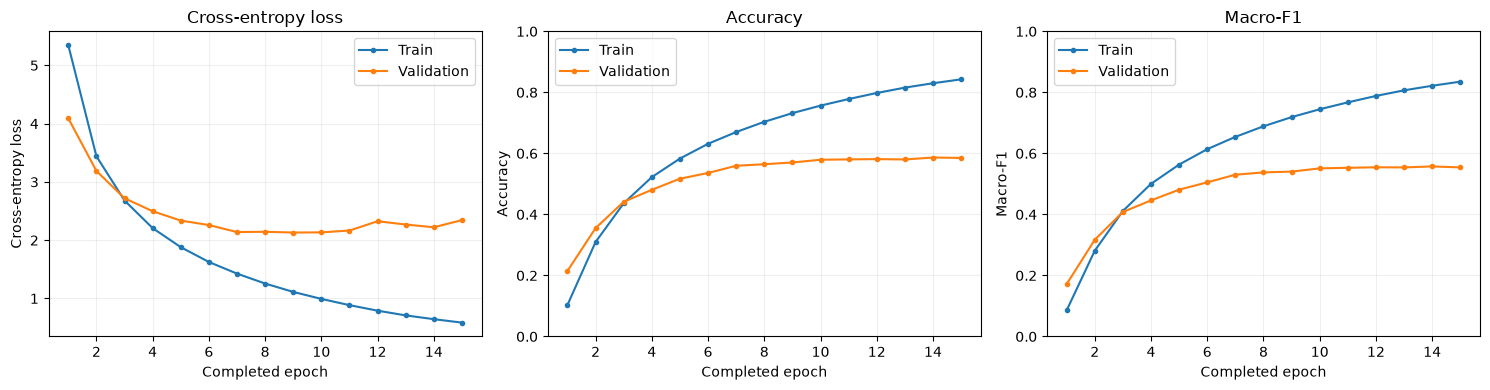

In [4]:
history = read_csv('history.csv')
if history is not None and 'epoch' in history:
    history['epoch'] = pd.to_numeric(history['epoch'], errors='coerce')
    required = ['epoch'] + [column for column in ['val_accuracy', 'val_macro_f1']
                            if column in history]
    history = history.dropna(subset=required).sort_values('epoch').copy()
if history is None or history.empty or 'epoch' not in history:
    print('Pending: history.csv with at least one completed epoch.')
else:
    table = history.copy()
    for column in list(table.columns):
        if 'accuracy' in column or 'macro_f1' in column:
            table[column] = pd.to_numeric(table[column], errors='coerce') * 100
            table = table.rename(columns={column: column + '_percent'})
    display(table.round(4))
    selection = 'val_accuracy' if EXPECTED_TASK == 'face' else 'val_macro_f1'
    if selection in history:
        scores = pd.to_numeric(history[selection], errors='coerce')
        if scores.notna().any():
            best = history.loc[scores.idxmax()]
            print(f"Completed epochs: {int(history['epoch'].max())}")
            print(f"Best epoch by {selection}: {int(best['epoch'])}, score: {float(best[selection]):.2%}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for axis, metric, title in zip(axes, ['loss', 'accuracy', 'macro_f1'],
                                   ['Cross-entropy loss', 'Accuracy', 'Macro-F1']):
        plotted = False
        for split, label in [('train', 'Train'), ('val', 'Validation')]:
            column = f'{split}_{metric}'
            if column in history:
                axis.plot(history['epoch'], history[column], marker='o', markersize=3, label=label)
                plotted = True
        axis.set(xlabel='Completed epoch', ylabel=title, title=title)
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        if metric != 'loss':
            axis.set_ylim(0, 1)
        if plotted:
            axis.legend()
        axis.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## 4. Saved classification evaluation
These values come from the saved evaluation JSON. They are not calculated from training
accuracy. The recorded `split` tells you whether the evaluation used validation or test.
Continuing training can change `best.pt`, so the checkpoint check identifies older results.

In [5]:
classification = read_json('classification/classification_metrics.json')
if classification is None:
    print('Pending: classification/classification_metrics.json. Run evaluation in Terminal first.')
else:
    check_evaluation_identity(classification, 'Classification evaluation')
    print('Task:', classification.get('task'), '| Split:', classification.get('split'),
          '| Samples:', classification.get('samples'))
    rows = [{'Metric': key, 'Percent': float(classification[key]) * 100}
            for key in ['accuracy', 'balanced_accuracy', 'macro_f1'] if key in classification]
    display(pd.DataFrame(rows).round(3))

Classification evaluation: checkpoint matches current best.pt.
Task: face | Split: test | Samples: 8000


,Metric,Percent
0,accuracy,59.150
1,balanced_accuracy,59.150
2,macro_f1,56.652


## 5. Saved face verification results
ROC-AUC measures ranking of same-person versus different-person pairs. TPR, FPR, and accuracy
depend on the saved threshold. Read the saved evaluation scope before making claims about
generalization. Threshold selection on the same validation pairs is not an independent test.
Cosine and negative Euclidean scores are both higher-is-more-similar in this project.

In [6]:
verification = read_json('verification/verification_metrics.json')
thresholds = read_json('verification/thresholds.json')
if verification is None:
    print('Pending: verification/verification_metrics.json. Run verification evaluation in Terminal first.')
else:
    check_evaluation_identity(verification, 'Verification evaluation')
    print('Scope:', verification.get('scope', 'not recorded'))
    print('Pairs:', verification.get('pairs'))
    print('Target calibration FPR:', verification.get('target_calibration_fpr'))
    rows = []
    for metric, values in verification.get('metrics', {}).items():
        rows.append({'Metric': metric, 'ROC-AUC': values.get('roc_auc'),
                     'Threshold': values.get('threshold'),
                     'TPR_percent': values.get('tpr', float('nan')) * 100,
                     'FPR_percent': values.get('fpr', float('nan')) * 100,
                     'Accuracy_percent': values.get('accuracy', float('nan')) * 100})
    display(pd.DataFrame(rows).round(4))
    if verification.get('note'):
        print('Limitation:', verification['note'])
    if classification and classification.get('checkpoint_sha256') != verification.get('checkpoint_sha256'):
        display(Markdown('**Classification and verification results refer to different checkpoints.**'))
if thresholds:
    print('Score rule:', thresholds.get('score_rule'))
    display(pd.DataFrame(thresholds.get('thresholds', {}).items(), columns=['Metric', 'Threshold']))
    if verification and thresholds.get('checkpoint_sha256') != verification.get('checkpoint_sha256'):
        display(Markdown('**Threshold file and verification metrics refer to different checkpoints.**'))

Verification evaluation: checkpoint matches current best.pt.
Scope: validation only; threshold selected on these same pairs
Pairs: 8805
Target calibration FPR: 0.01


,Metric,ROC-AUC,Threshold,TPR_percent,FPR_percent,Accuracy_percent
0,cosine,0.9065,0.4886,25.4693,0.98,62.9756
1,negative_euclidean,0.9065,-1.0113,25.4693,0.98,62.9756


Limitation: Pairwise thresholds require separate validation for 1:N gallery matching. No guaranteed webcam FPR.
Score rule: accept if score >= threshold


,Metric,Threshold
0,cosine,0.488597
1,negative_euclidean,-1.011339


## 6. Saved ROC image
This displays the ROC image created by evaluation. It does not read the face dataset
or compute embeddings. The training curves above are drawn directly from `history.csv`.

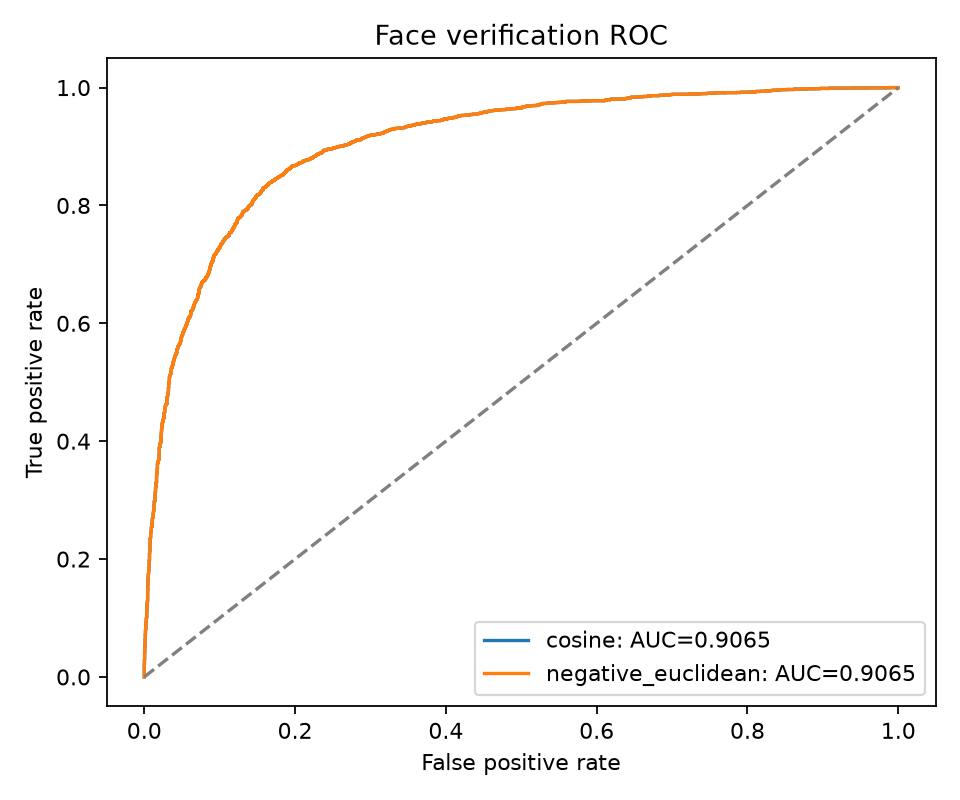

In [7]:
show_image('verification/roc.png')

## 7. Discussion to complete after the experiment
- Describe how loss and validation accuracy change across completed epochs.
- Report test classification accuracy separately from pairwise verification ROC-AUC.
- Compare both embedding approaches on the same verification pairs with the teammate.
- Explain threshold calibration, unknown-person errors, and webcam domain differences.
- For normalized embeddings, squared Euclidean distance equals `2 - 2*cosine`, so their
  rankings should be equivalent apart from numerical ties.
- Do not claim independent testing if these pairs were used for model selection or calibration.